# 10 — Melhorias de confiança (M1 a M10)

> **Registro do estudo que levou à D-046.** Este notebook foi rodado com o banco de antes da D-046 (premissas v2, sem a regra do salto). O autor decidiu em 28/10/2026, a partir dele: (1) recalibrar a chance e a parte descoberta do déficit pela M1 (premissas v3); (2) manter o valor declarado na classe, com aviso e sensibilidade para os saltos grosseiros; (3) não usar coleta nova: os dados continuam os de 17 e 18/10. Os 10 números novos estão no notebook 09. Rodar este notebook no banco atual dá outros números nas seções 1 a 3, porque o "modelo" passa a ser a v3.

**Para que serve este notebook.** A validação de todos os notebooks (`docs/diario.md`, 2026-10-27) apontou onde a confiança é baixa e propôs dez melhorias (`docs/plano_mineracao.md`, "Melhorias de confiança"). Este notebook faz oito delas, uma por seção, e responde: **com dado em vez de suposição, o que muda nas conclusões do notebook 09?** A M9 (duas coletas do cadastro) e as partes da M3 e da M6 que comparavam coletas ficaram de fora: dependiam de uma coleta nova, que o autor decidiu não usar.

| Seção | Melhoria | Ponto fraco que ela ataca |
|---|---|---|
| 1 | **M1** capacidade de pagar | degraus 5 e 6 (quem tem déficit e quanto) eram só suposição |
| 2 | **M10** grupos pelo déficit da M1 | a leitura dos grupos dependia da suposição |
| 3 | **M2** sinistro por frequência × severidade | a pergunta 9 (a seguradora tem lucro?) não tinha análise |
| 4 | **M7** prêmio por cenário do STF | o risco jurídico ficava fora da faixa do prêmio |
| 5 | **M8** taxa e adesão | as duas suposições que mais mexem no prêmio, sem fonte |
| 6 | **M5** passivo projetado | o prêmio projetado usava o passivo de 2025 |
| 7 | **M3** previsão de 2026–27 | previsão conservadora e faixas mal calibradas |
| 8 | **M4** subidas de classe | duas contagens de subidas que não batiam (07 × 05b) |
| 9 | **M6** universo | a leitura da norma muda quem é obrigado |

**Regra:** **nenhum dos 10 números do painel muda aqui.** Tudo é **sensibilidade** ou **projeção**, rotulado como tal. Se uma melhoria indicar que a base deveria mudar, isso vira proposta para o autor (seção 10), não mudança.

**Dados:**
- banco do pipeline (dados da carga de 19/10/2026, banco refeito em 28/10, antes da D-046), premissas v2, regra v2, cenário do STF "mantém";
- o CSV do BI do CNJ no bronze (arrecadação, repasse e custeio por serventia, 2025).

Os gráficos também vão em PNG para `docs/qa/analises/` (`10_*.png`). O cálculo fica em `src/analise/melhorias.py`, com testes em `tests/test_analise_melhorias.py`; as tabelas para o painel, em `src/analise/tabelas.py`.

**Termos usados:** saldo do titular, meses de saldo, horizonte, frequência e severidade, sinistralidade, índice combinado, resultado técnico, cobertura de uma faixa, teste no passado (origem móvel), MAPE, viés, intervalo de confiança (IC). Cada um é explicado onde aparece pela primeira vez.

A linha abaixo confere que estamos no mesmo modelo do painel (números 3, 7, 8 e 9).

In [1]:
import sys
import warnings
from pathlib import Path

raiz = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(raiz))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

from src import estado
from src.analise import classificacao as cl, config, dados, estatistica as est, graficos as g
from src.analise import melhorias as mh, previsao as pv
from src.motor import premissas_nivel
from src.notebooks import conectar
from src.transform.gold import carregar_insumos

g.estilo()
cfg = config()
mc_cfg = cfg["melhorias"]
con = conectar()
sv = dados.serventias(con)
semente_premissas = yaml.safe_load((raiz / "config/premissas/premissas_v002.yaml").read_text(encoding="utf-8"))  # a v2: o estudo é de antes da D-046
cenarios = yaml.safe_load((raiz / "config/cenarios_stf.yaml").read_text(encoding="utf-8"))
limites = yaml.safe_load((raiz / "config/regras_classificacao.yaml").read_text(encoding="utf-8"))["versoes"]["v2"]["limites"]
peso = con.execute("SELECT peso_classe_indeterminada_base FROM gold.execucao WHERE regra_classe = 'v2'").fetchone()[0]
p = premissas_nivel(semente_premissas, "base", peso)
oficial = con.execute("""SELECT n_universo, passivo_universo, valor_descoberto, mercado_importancia_segurada,
    mercado_premio_emitido FROM gold.fato_mercado_uf WHERE nivel = 'base' AND regra_classe = 'v2'
    AND cenario_stf = 'mantem'""").df().iloc[0]
FONTE = "dados da carga de 19/10/2026 (banco refeito em 28/10); premissas v2; regra v2; STF \"mantém\""
print(f"Obrigadas: {g.num(oficial.n_universo, 1)}; déficit: {g.reais(oficial.valor_descoberto)}; "
      f"IS: {g.reais(oficial.mercado_importancia_segurada)}; prêmio: {g.reais(oficial.mercado_premio_emitido)} (números 3, 7, 8 e 9).")

Obrigadas: 1.121,3; déficit: R$ 36,9 mi; IS: R$ 18,4 mi; prêmio: R$ 368,7 mil (números 3, 7, 8 e 9).


## 1. M1 — O titular consegue pagar o passivo com a renda do cartório?

**A pergunta.** O modelo **supõe** que 50% das obrigadas da Classe 2 e 30% das da Classe 3 têm déficit, e que o déficit é 50% e 40% do passivo (D-016, `fonte: suposição`). Dá para trocar essa suposição por um dado?

**O método.**
- O **saldo do titular** é o que sobra da arrecadação do cartório depois do **repasse** (o que vai para o Estado, o Tribunal e os fundos) e do **custeio** (as despesas de funcionamento, inclusive a folha). Os três vêm do BI do CNJ, por serventia, em 2025. Saldo é **renda** do titular, não patrimônio: o patrimônio de pessoa física não é público.
- **Meses de saldo** = passivo ÷ (saldo anual ÷ 12). Exemplo: passivo de R$ 120 mil e saldo de R$ 480 mil por ano (R$ 40 mil por mês) dão 3 meses.
- **Horizonte:** supomos que o titular consegue dedicar ao passivo até **12 meses de saldo** (`fonte: suposição`; 6 e 24 meses como sensibilidade). A **capacidade** é saldo × 12 ÷ 12 = um ano de saldo. Se o passivo passa da capacidade, a serventia **não cobre** e o que sobra é o **descoberto pela M1**. Exemplo: passivo de R$ 1,2 mi e saldo de R$ 600 mil: a capacidade é R$ 600 mil e o descoberto, R$ 600 mil (50% do passivo).
- **Cuidados com o BI:** no 2º semestre de 2025 o BI repete o custeio da serventia em cada linha de atribuição; aqui ele conta uma vez só (8.183 períodos). Quem só tem um semestre com dado tem o saldo anualizado (× 2).

**Por que este método.** É a medida F6 da verificação de 18/10 (`docs/diario.md`), com as mesmas faixas (< 3, 3 a 12, > 12 meses, saldo ≤ 0, sem dado), agora por serventia e ligada ao déficit do modelo.

In [2]:
saldo = dados.saldo_bi(con, mc_cfg["capacidade"]["ano"])
cap = mh.capacidade(sv, saldo)
fx = mh.tabela_faixas(cap)
display(g.tabela(fx.reset_index(), {"serventias": "int", "obrigadas": "num1", "passivo_obrigadas": "reais",
                                    "deficit_modelo": "reais", "pct_obrigadas": "pct", "pct_deficit_modelo": "pct"})
        .rename(columns={"faixa_meses": "meses de saldo para pagar o passivo", "passivo_obrigadas": "passivo das obrigadas",
                         "deficit_modelo": "déficit do modelo", "pct_obrigadas": "% das obrigadas",
                         "pct_deficit_modelo": "% do déficit do modelo"}))
com = cap[cap.saldo_anual > 0]
print(f"Obrigadas com dado do BI em {mc_cfg['capacidade']['ano']}: {g.num(cap.saldo_anual.notna().sum())} de {g.num(len(cap))} "
      f"({g.num((cap.semestres == 1).sum())} com um semestre só, anualizado). Saldo anual mediano: {g.reais(com.saldo_anual.median())}; "
      f"meses de saldo medianos: {g.num(com.meses_de_saldo.median(), 2)}. Agregado: passivo das obrigadas ÷ saldo mensal somado = "
      f"{g.num(cap.passivo.sum() / (cap.saldo_anual.clip(lower=0).sum() / 12), 2)} meses.")
s0 = cap[cap.saldo_anual <= 0]
print(f"Saldo ≤ 0: {g.num(len(s0))} obrigadas; custeio declarado maior que arrecadação − repasse. Mediana do custeio ÷ "
      f"(arrecadação − repasse): {g.num((s0.custeio_bi / (s0.arrecadacao_bi - s0.repasse_bi)).median(), 2)}.")

,meses de saldo para pagar o passivo,serventias,obrigadas,passivo das obrigadas,déficit do modelo,% das obrigadas,% do déficit do modelo
0,< 3 meses,810,"810,0","R$ 133,0 mi","R$ 20,6 mi","72,2%","55,9%"
1,3 a 12 meses,205,"205,0","R$ 63,7 mi","R$ 10,1 mi","18,3%","27,4%"
2,> 12 meses,35,"35,0","R$ 16,8 mi","R$ 2,4 mi","3,1%","6,6%"
3,saldo ≤ 0,50,"50,0","R$ 22,2 mi","R$ 3,1 mi","4,5%","8,4%"
4,sem dado,30,"21,3","R$ 2,4 mi","R$ 595,2 mil","1,9%","1,6%"


Obrigadas com dado do BI em 2025: 1.100 de 1.130 (94 com um semestre só, anualizado). Saldo anual mediano: R$ 609,3 mil; meses de saldo medianos: 1,59. Agregado: passivo das obrigadas ÷ saldo mensal somado = 1,96 meses.
Saldo ≤ 0: 50 obrigadas; custeio declarado maior que arrecadação − repasse. Mediana do custeio ÷ (arrecadação − repasse): 1,14.


**Como ler.** Cada linha é uma faixa de meses de saldo. "% do déficit do modelo" mostra onde o modelo de hoje põe o déficit.

**O que encontramos.**
- **72% das obrigadas pagariam o passivo inteiro com menos de 3 meses de saldo**, e mais 18% com 3 a 12 meses. Só **35 (3%) precisariam de mais de um ano**.
- O passivo de todas as obrigadas equivale a **2 meses** do saldo somado delas. A mediana é 1,6 mês.
- **50 obrigadas têm saldo ≤ 0**: o custeio declarado passa da arrecadação menos o repasse (na mediana, 1,14 vez). É mais provável erro ou atraso de declaração do que prejuízo real de um cartório obrigado a ter garantia.
- Mesmo assim, o modelo põe **56% do déficit** nas que pagariam com menos de 3 meses de saldo.

**As faixas de 18/10 eram outras** (708, 260, 41, 47 e 74): lá, quem não tinha os dois semestres ficou como "sem dado" e o custeio repetido não foi tratado. Aqui, 94 obrigadas com um semestre só foram anualizadas.

,faixa de déficit,obrigadas,com dado do BI,chance de déficit: modelo,chance de déficit: M1,parte descoberta: modelo,parte descoberta: M1,déficit: modelo,déficit: M1
0,classe_2,"767,3","739,0","50,0%","6,9%","50,0%","68,3%","R$ 16,0 mi","R$ 5,1 mi"
1,classe_3,"354,0","354,0","30,0%","9,6%","40,0%","90,7%","R$ 20,9 mi","R$ 29,4 mi"


,leitura,déficit,IS,prêmio,variação sobre o modelo
0,modelo (premissas vigentes),"R$ 36,9 mi","R$ 18,4 mi","R$ 368,7 mil","0,0%"
1,M1: 6 meses de saldo,"R$ 45,9 mi","R$ 23,0 mi","R$ 459,3 mil","24,6%"
2,M1: 12 meses de saldo,"R$ 34,5 mi","R$ 17,2 mi","R$ 345,0 mil","-6,4%"
3,M1: 24 meses de saldo,"R$ 30,8 mi","R$ 15,4 mi","R$ 308,2 mil","-16,4%"


Do déficit da M1 com 12 meses (R$ 34,5 mi), R$ 22,2 mi (64,4%) vêm das 50 obrigadas com saldo ≤ 0 (o passivo inteiro fica descoberto).


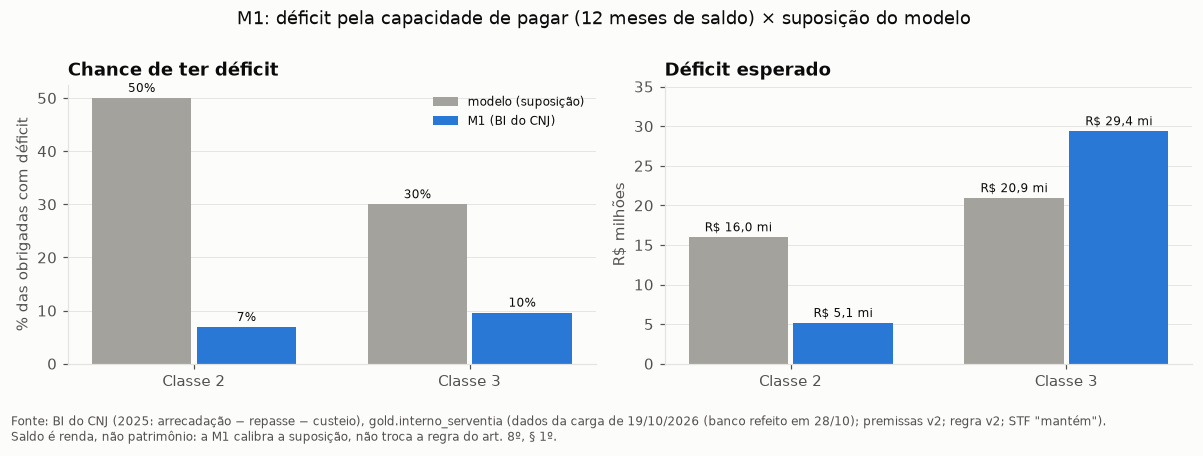

In [3]:
cal = mh.calibracao(cap, p)
display(g.tabela(cal.reset_index(), {"obrigadas": "num1", "com_dado_bi": "num1", "prob_deficit_modelo": "pct",
                                     "prob_deficit_m1": "pct", "pct_descoberto_modelo": "pct", "pct_descoberto_m1": "pct",
                                     "deficit_modelo": "reais", "deficit_m1": "reais"})
        .rename(columns={"faixa_deficit": "faixa de déficit", "com_dado_bi": "com dado do BI",
                         "prob_deficit_modelo": "chance de déficit: modelo", "prob_deficit_m1": "chance de déficit: M1",
                         "pct_descoberto_modelo": "parte descoberta: modelo", "pct_descoberto_m1": "parte descoberta: M1",
                         "deficit_modelo": "déficit: modelo", "deficit_m1": "déficit: M1"}))
hz = mh.deficit_por_horizonte(sv, saldo, p)
hz["variação sobre o modelo"] = hz.deficit / hz.deficit.iloc[0] - 1
display(g.tabela(hz.drop(columns="horizonte_meses"), {"deficit": "reais", "importancia_segurada": "reais", "premio": "reais",
                                                      "variação sobre o modelo": "pct"})
        .rename(columns={"deficit": "déficit", "importancia_segurada": "IS", "premio": "prêmio"}))
d0 = (cap.peso_universo * cap.descoberto_m1)[cap.saldo_anual <= 0].sum()
print(f"Do déficit da M1 com 12 meses ({g.reais(mh.deficit_m1(cap))}), {g.reais(d0)} ({g.pct(d0 / mh.deficit_m1(cap))}) vêm das "
      f"{g.num((cap.saldo_anual <= 0).sum())} obrigadas com saldo ≤ 0 (o passivo inteiro fica descoberto).")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
x = np.arange(len(cal))
for j, (col, nome, cor) in enumerate([("prob_deficit_modelo", "modelo (suposição)", g.CINZA), ("prob_deficit_m1", "M1 (BI do CNJ)", g.AZUL["medio"])]):
    b = axs[0].bar(x + (j - 0.5) * 0.38, 100 * cal[col], width=0.36, color=cor, label=nome)
    axs[0].bar_label(b, [g.pct(v, 0) for v in cal[col]], padding=2, fontsize=8)
axs[0].set_xticks(x, ["Classe 2", "Classe 3"])
axs[0].set_ylabel("% das obrigadas com déficit")
axs[0].set_title("Chance de ter déficit")
axs[0].legend(fontsize=8)
for j, (col, nome, cor) in enumerate([("deficit_modelo", "modelo (suposição)", g.CINZA), ("deficit_m1", "M1 (BI do CNJ)", g.AZUL["medio"])]):
    b = axs[1].bar(x + (j - 0.5) * 0.38, cal[col] / 1e6, width=0.36, color=cor, label=nome)
    axs[1].bar_label(b, [g.reais(v) for v in cal[col]], padding=2, fontsize=8)
axs[1].set_xticks(x, ["Classe 2", "Classe 3"])
axs[1].set_ylabel("R$ milhões")
axs[1].set_ylim(0, cal[["deficit_modelo", "deficit_m1"]].max().max() / 1e6 * 1.2)
axs[1].set_title("Déficit esperado")
for ax in axs:
    ax.grid(axis="x", visible=False)
fig.suptitle("M1: déficit pela capacidade de pagar (12 meses de saldo) × suposição do modelo", y=1.0)
fig.tight_layout()
g.nota(fig, f"Fonte: BI do CNJ (2025: arrecadação − repasse − custeio), gold.interno_serventia ({FONTE}).\nSaldo é renda, não patrimônio: "
            "a M1 calibra a suposição, não troca a regra do art. 8º, § 1º.")
g.salvar(fig, "10_capacidade_de_pagar")
plt.show()

**Como ler.** A primeira tabela compara, por faixa de déficit, a suposição do modelo com a medida pela M1 (12 meses de saldo). A segunda mostra o déficit total, a IS e o prêmio para cada horizonte. O gráfico resume a primeira tabela.

**O que encontramos.**
- **Poucas obrigadas têm déficit pela renda:** 6,9% na Classe 2 e 9,6% na Classe 3, contra 50% e 30% supostos. Mas **quem tem déficit tem um déficit grande:** 68% e 91% do passivo, contra 50% e 40%.
- **O total quase não muda:** R$ 34,5 mi pela M1, contra R$ 36,9 mi do modelo (−6%; prêmio R$ 345 mil). Com 6 meses de saldo, R$ 45,9 mi (+25%); com 24 meses, R$ 30,8 mi (−16%).
- **A composição muda muito:** pela M1 o déficit da Classe 2 cai de R$ 16,0 mi para R$ 5,1 mi, e o da Classe 3 sobe de R$ 20,9 mi para R$ 29,4 mi.
- **Ressalva forte:** 64% do déficit da M1 vem das 50 obrigadas com saldo ≤ 0, que ficam com o passivo inteiro descoberto. Se o saldo negativo for erro de declaração, o déficit pela M1 é menor.

**O que significa para o Prov. 227.** A suposição do modelo erra a forma, mas acerta a ordem de grandeza: o mercado é **de poucas apólices grandes**, concentradas na Classe 3, e não de muitas apólices pequenas espalhadas pela Classe 2. O total da base (número 7) continua defensável. A proposta para o autor é usar a M1 para recalibrar a **chance** e a **parte descoberta** por classe, mantendo o total como faixa (seção 10; decidido na D-046).

**Limitações.** Saldo é renda, não patrimônio (o art. 8º, § 1º fala em patrimônio). O horizonte de 12 meses é suposição. O custeio do BI é declarado pelo próprio cartório e pode incluir a remuneração do titular, o que deixaria o saldo menor do que a renda real. 30 obrigadas (21 em peso) não têm dado do BI e ficam com o déficit do modelo.

## 2. M10 — Os grupos do notebook 04 pelo déficit da M1

**A pergunta.** O notebook 09 (achado 5) mostrou que as "providas grandes" têm 55% do déficit, mas esse número depende da suposição. Com a M1, o grupo continua sendo o cliente principal?

**O método.** A parte de cada grupo do k-means do notebook 04 (`gold.analise_grupos`) nas obrigadas, no passivo das obrigadas (dado), no déficit do modelo (suposição) e no déficit pela M1 (12 meses de saldo). Os grupos 1 e 5 (vagas) não aparecem: não têm obrigadas.

In [4]:
grp = mh.grupos_com_m1(cap, con.sql("SELECT * FROM gold.analise_grupos").df())
display(g.tabela(grp[["grupo", "nome_grupo", "obrigadas", "pct_obrigadas", "pct_passivo_obrigadas", "pct_deficit_modelo", "pct_deficit_m1"]],
                 {"obrigadas": "num1", "pct_obrigadas": "pct", "pct_passivo_obrigadas": "pct", "pct_deficit_modelo": "pct",
                  "pct_deficit_m1": "pct"})
        .rename(columns={"nome_grupo": "grupo (notebook 04)", "pct_obrigadas": "% das obrigadas",
                         "pct_passivo_obrigadas": "% do passivo das obrigadas (dado)", "pct_deficit_modelo": "% do déficit: modelo",
                         "pct_deficit_m1": "% do déficit: M1"}))

,grupo,grupo (notebook 04),obrigadas,% das obrigadas,% do passivo das obrigadas (dado),% do déficit: modelo,% do déficit: M1
0,2,providas pequenas (Notas e RCPN),"300,0","27,2%","9,4%","14,7%","3,9%"
1,3,providas médias de uma atribuição,"383,0","34,7%","13,0%","19,8%","5,7%"
2,4,"registro completo (RI, RTD e RCPJ)","159,0","14,4%","9,6%","10,1%","5,5%"
3,6,providas grandes,"261,0","23,7%","68,0%","55,4%","84,9%"


**O que encontramos.** Pela M1, as **providas grandes** (24% das obrigadas) ficam com **85% do déficit**, contra 55% no modelo e 68% do passivo. Os outros três grupos somam 15%.

**O que significa.** O achado 5 do 09 fica **mais forte** com dado: o cliente do seguro é o grupo das providas grandes (265 serventias, receita mediana de R$ 3,3 mi por semestre).

**Limitações.** As da M1 (seção 1). Os grupos são os do notebook 04, com a semente de `config/analise.yaml`.

## 3. M2 — A seguradora tem lucro? (pergunta 9)

**A pergunta.** O seguro paga quando a **delegação termina** (morte, aposentadoria, renúncia, perda) e o titular deixa o passivo sem pagar. Quanto isso custa à seguradora, comparado com o prêmio?

**O método (frequência × severidade).**
- **Frequência:** a chance de a delegação terminar no ano, P(fim). Vem do notebook 05c: **2%** (mínimo), **4%** (base) e **7,5%** (máximo) ao ano (`config/analise.yaml`, `melhorias.sinistro`).
- **Severidade q:** a parte da IS que vira sinistro quando a delegação termina. Sem a M1, q = 100% (ninguém paga nada). Com a M1, para cada obrigada, q = a parte do déficit do modelo que o titular **não** paga com 12 meses de saldo, e o total é a média ponderada pelo déficit.
- **Sinistro esperado** = P(fim) × q × IS. **Sinistralidade** = sinistro ÷ prêmio = P(fim) × q ÷ taxa. Exemplo: P(fim) de 4%, q de 50% e taxa de 2% dão 4% × 50% ÷ 2% = 100% (o sinistro igual ao prêmio).
- **Índice combinado** = sinistralidade + comissão + despesa administrativa (premissas: 17,1% e 8,0% na base). Abaixo de 100%, a seguradora tem lucro técnico. **Resultado técnico** = prêmio × (1 − índice combinado), antes de impostos, resseguro e capital.
- Junto, as **apólices esperadas** e o **prêmio médio** (o B3 de 18/10).

**Por que este método.** É a proposta da D-025 (frequência × severidade), com a frequência do 05c e a severidade da M1. A sinistralidade da SES da SUSEP (1,7% a 73,9%, base 10,9%) vem de outra carteira (garantia de obras e contratos) e fica só para comparar.

,leitura,P(fim),P(fim da delegação no ano),parte da IS que vira sinistro,sinistro esperado/ano,sinistralidade,índice combinado,resultado técnico/ano
0,sem a M1: o titular não paga nada,min,"2,0%","100,0%","R$ 368,7 mil","100,0%","125,1%","R$ -92,6 mil"
1,sem a M1: o titular não paga nada,base,"4,0%","100,0%","R$ 737,5 mil","200,0%","225,1%","R$ -461,3 mil"
2,sem a M1: o titular não paga nada,max,"7,5%","100,0%","R$ 1,4 mi","375,0%","400,1%","R$ -1,1 mi"
3,com a M1: paga até o horizonte de saldo,min,"2,0%","12,3%","R$ 45,5 mil","12,3%","37,4%","R$ 230,7 mil"
4,com a M1: paga até o horizonte de saldo,base,"4,0%","12,3%","R$ 91,1 mil","24,7%","49,8%","R$ 185,1 mil"
5,com a M1: paga até o horizonte de saldo,max,"7,5%","12,3%","R$ 170,7 mil","46,3%","71,4%","R$ 105,5 mil"


Prêmio do mercado: R$ 368,7 mil; apólices esperadas (B3): 243; prêmio médio por apólice: R$ 1,52 mil. Comissão 17,1% e despesa 8,0% (premissas, base). Sinistralidade da SES (premissas): 10,9% na base (de 1,7% a 73,9%).
Com P(fim) de 4,0% e taxa de 2,0%, o resultado técnico zera quando a parte da IS que vira sinistro chega a 37,5%.


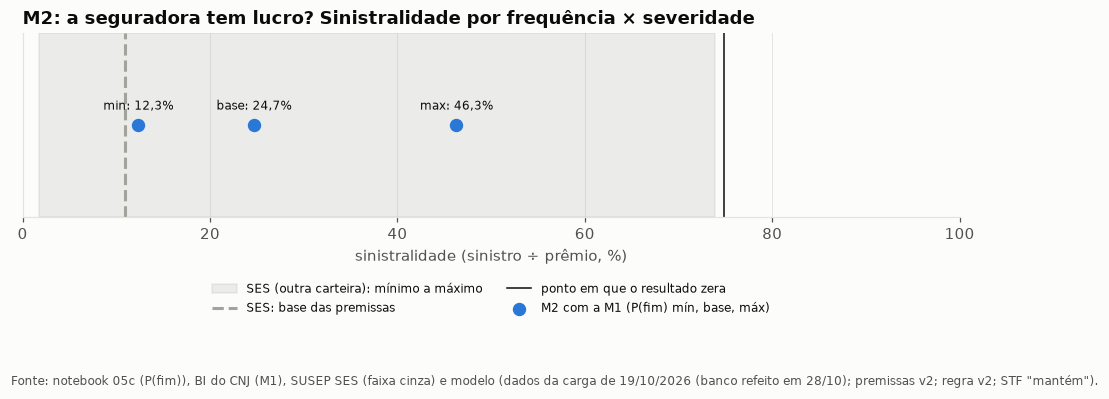

In [5]:
sin = mh.sinistro(cap, p)
display(g.tabela(sin[["leitura", "nivel_p_fim", "p_fim", "severidade_q", "sinistro_esperado", "sinistralidade", "indice_combinado",
                      "resultado_tecnico"]],
                 {"p_fim": "pct", "severidade_q": "pct", "sinistro_esperado": "reais", "sinistralidade": "pct",
                  "indice_combinado": "pct", "resultado_tecnico": "reais"})
        .rename(columns={"nivel_p_fim": "P(fim)", "p_fim": "P(fim da delegação no ano)", "severidade_q": "parte da IS que vira sinistro",
                         "sinistro_esperado": "sinistro esperado/ano", "indice_combinado": "índice combinado",
                         "resultado_tecnico": "resultado técnico/ano"}))
r = sin.iloc[0]
print(f"Prêmio do mercado: {g.reais(r.premio)}; apólices esperadas (B3): {g.num(r.apolices)}; prêmio médio por apólice: "
      f"{g.reais(r.premio_medio, 2)}. Comissão {g.pct(p['comissao'])} e despesa {g.pct(p['despesa_administrativa'])} (premissas, base). "
      f"Sinistralidade da SES (premissas): {g.pct(p['sinistralidade'])} na base (de {g.pct(semente_premissas['premissas']['sinistralidade']['valores']['min'])} "
      f"a {g.pct(semente_premissas['premissas']['sinistralidade']['valores']['max'])}).")
q_zero = (1 - p["comissao"] - p["despesa_administrativa"]) * p["taxa_seguro_anual"] / mc_cfg["sinistro"]["p_fim"]["base"]
print(f"Com P(fim) de {g.pct(mc_cfg['sinistro']['p_fim']['base'])} e taxa de {g.pct(p['taxa_seguro_anual'])}, o resultado técnico zera "
      f"quando a parte da IS que vira sinistro chega a {g.pct(q_zero)}.")

fig, ax = plt.subplots(figsize=(9, 3.4))
m1 = sin[sin.leitura.str.startswith("com")]
ax.axvspan(100 * semente_premissas["premissas"]["sinistralidade"]["valores"]["min"],
           100 * semente_premissas["premissas"]["sinistralidade"]["valores"]["max"], color=g.CINZA, alpha=0.18,
           label="SES (outra carteira): mínimo a máximo")
ax.axvline(100 * p["sinistralidade"], color=g.CINZA, linestyle="--", label="SES: base das premissas")
ax.axvline(100 * (1 - p["comissao"] - p["despesa_administrativa"]), color=g.TEXTO, linewidth=1, label="ponto em que o resultado zera")
ax.scatter(100 * m1.sinistralidade, np.zeros(len(m1)), s=60, color=g.AZUL["medio"], zorder=3, label="M2 com a M1 (P(fim) mín, base, máx)")
for v, n in zip(m1.sinistralidade, m1.nivel_p_fim):
    ax.annotate(f"{n}: {g.pct(v)}", (100 * v, 0), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=8)
ax.set_yticks([])
ax.set_xlim(0, 100)
ax.set_xlabel("sinistralidade (sinistro ÷ prêmio, %)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2, fontsize=8)
ax.set_title("M2: a seguradora tem lucro? Sinistralidade por frequência × severidade")
fig.tight_layout()
g.nota(fig, f"Fonte: notebook 05c (P(fim)), BI do CNJ (M1), SUSEP SES (faixa cinza) e modelo ({FONTE}).")
g.salvar(fig, "10_sinistralidade")
plt.show()

**Como ler.** As três primeiras linhas supõem que nenhum titular paga nada (q = 100%); as três últimas usam a M1. O gráfico mostra a sinistralidade com a M1 contra a faixa da SES (cinza) e o ponto em que o resultado zera (74,9% = 100% − comissão − despesa).

**O que encontramos.**
- **Sem a M1, a seguradora perde dinheiro em qualquer cenário:** a sinistralidade vai de 100% a 375%, e o prejuízo, de R$ 93 mil a R$ 1,1 mi por ano. Com P(fim) de 4% e taxa de 2%, ela só cobre os custos se no máximo **37,5% da IS** virar sinistro.
- **Com a M1, a seguradora tem lucro:** só 12,3% da IS vira sinistro (os titulares pagam a maior parte com a renda), e a sinistralidade fica entre **12% e 46%** (base 25%). O índice combinado vai de 37% a 71%, e o resultado técnico, de **R$ 106 mil a R$ 231 mil por ano** (base R$ 185 mil).
- **O mercado é pequeno em apólices:** cerca de 243 apólices, com prêmio médio de **R$ 1,5 mil por ano**.

**O que significa para o Prov. 227.** A resposta da pergunta 9 depende de **quem paga quando a delegação termina**. Pela renda declarada ao CNJ, a maior parte dos titulares conseguiria pagar, e o seguro seria lucrativo, com sinistralidade acima da SES (25% contra 10,9%). Se os titulares não pagarem (herdeiros sem a renda do cartório, por exemplo), o seguro dá prejuízo com a taxa de 2%: precisaria de uma taxa de pelo menos ≈ 5,3% (4% ÷ 75%).

**Limitações.** A P(fim) do 05c tem viés de sobrevivência e pode estar baixa. Quando a delegação termina por morte, a renda do titular acaba: a severidade da M1 pode estar baixa justamente no caso mais comum. Não há impostos, resseguro nem custo de capital. Prêmio médio de R$ 1,5 mil está abaixo de qualquer prêmio mínimo de mercado (o B3 de 18/10): o mercado real seria ainda menor em número de apólices.

## 4. M7 — O prêmio em cada cenário do STF

**A pergunta.** A ADI 8015 questiona os arts. 8º a 17 do Prov. 227 no STF. Como fica o prêmio em cada desfecho?

**O método.** A demanda de garantia é proporcional à parte do déficit que continua exigida (`config/cenarios_stf.yaml`): 100% se a regra se mantém, 50% no cenário hipotético "parcial" (`fonte: suposição`) e 0% se os arts. 8º a 17 forem suspensos. O prêmio de cada cenário é o do "mantém" × essa parte, no valor base e na faixa P5–P95 do Monte Carlo (`gold.analise_monte_carlo`).

In [6]:
mc = con.sql("SELECT * FROM gold.analise_monte_carlo").df()
pc_stf = mh.premio_por_cenario(mc, cenarios)
display(g.tabela(pc_stf.drop(columns="descricao"), {"fracao_exigida": "pct", "premio_base": "reais", "premio_p05": "reais",
                                                    "premio_p50": "reais", "premio_p95": "reais"})
        .rename(columns={"cenario": "cenário do STF", "fracao_exigida": "parte do déficit exigida", "premio_base": "prêmio base",
                         "premio_p05": "P5", "premio_p50": "mediana", "premio_p95": "P95"}))
stf = (raiz / "data/bronze/stf/2026-10-17/adi_8015_abaAndamentos.html").read_text(encoding="utf-8", errors="ignore")
import html, re
datas = re.findall(r"andamento-data[^>]*>\s*([0-9/]+)", stf)
nomes = [html.unescape(n.strip()) for n in re.findall(r"andamento-nome[^>]*>\s*([^<]+)", stf)]
print("ADI 8015 no bronze (coleta de 17/10/2026), últimos andamentos: " + "; ".join(f"{d} {n}" for d, n in list(zip(datas, nomes))[:4]) + ".")

,cenário do STF,parte do déficit exigida,prêmio base,P5,mediana,P95
0,mantem,"100,0%","R$ 368,7 mil","R$ 206,1 mil","R$ 402,7 mil","R$ 736,2 mil"
1,suspende_8_17,"0,0%",R$ 0,R$ 0,R$ 0,R$ 0
2,parcial,"50,0%","R$ 184,4 mil","R$ 103,1 mil","R$ 201,3 mil","R$ 368,1 mil"


ADI 8015 no bronze (coleta de 17/10/2026), últimos andamentos: 16/10/2026 Petição; 14/10/2026 Petição; 14/10/2026 Publicação, DJE; 13/10/2026 Vista à PGR.


**O que encontramos.** Mantida a regra, o prêmio é de **R$ 368,7 mil** (faixa provável de R$ 206 a 736 mil). No cenário parcial, R$ 184 mil (R$ 103 a 368 mil). Com os arts. 8º a 17 suspensos, **zero**.

**Andamento da ADI 8015.**
- **No bronze (coleta de 17/10/2026):** rito do art. 12 da Lei 9.868/1999, sem liminar; vista à PGR em 13/10.
- **Conferido no portal do STF em 28/10/2026** (só leitura, sem gravar no bronze): duas decisões monocráticas "Deferido" em 22/10, seguidas de uma certidão que inclui dois sindicatos de notários e registradores no registro do processo. A leitura mais provável é a **admissão de terceiros interessados** (*amici curiae*), não uma liminar: o texto das decisões não aparece na aba pública. Em 27/10 houve nova petição de terceiro interessado e o processo foi concluso ao relator. **Nenhuma decisão de mérito nem liminar até 28/10.**

**O que significa para o painel.** O risco jurídico não cabe na faixa P5–P95: ele é **binário**. O painel deve mostrar o prêmio **condicionado ao cenário** ("se a regra for mantida"), com o "suspende = zero" ao lado, e conferir o andamento na véspera da apresentação.

**Limitações.** O cenário "parcial" é hipotético (até 28/10 não havia decisão parcial). A leitura das decisões de 22/10 é inferência a partir da certidão.

## 5. M8 — Taxa do seguro e adesão: há fonte? E, sem fonte, como mostrar?

**A pergunta.** A taxa do seguro (1% a 3,5% ao ano) e a parte das obrigadas que escolhe o seguro (25% a 70%) são as suposições que mais mexem no prêmio (notebook 08). (a) A SUSEP publica a importância segurada, de onde sairia a taxa média (prêmio ÷ IS)? (b) Se não, como mostrar o prêmio?

**O método.** (a) Conferimos as colunas do extrato da SES no bronze e, sem baixar os 577 MB, o índice do `BaseCompleta.zip` da SUSEP (40 tabelas) e o dicionário de campos (`Ses_campos.csv`, 2.036 itens), lidos por intervalo de bytes em 28/10/2026. (b) Uma grade: o prêmio com o déficit da base para cada combinação de taxa e adesão no mínimo, no base e no máximo das premissas.

Colunas do extrato da SES no bronze (ramos 0775 e 0776): damesano, coenti, cogrupo, coramo, premio_direto, premio_de_seguros, premio_retido, premio_ganho, sinistro_direto, sinistro_retido, desp_com, premio_emitido2, premio_emitido_cap, despesa_resseguros, sinistro_ocorrido, receita_resseguro, sinistros_ocorridos_cap, recuperacao_sinistros_ocorridos_cap, rvne, conveniodpvat, consorciosefundos.


,taxa anual,adesão de 25%,adesão de 50%,adesão de 70%
0,"1,0%","R$ 92,2 mil","R$ 184,4 mil","R$ 258,1 mil"
1,"2,0%","R$ 184,4 mil","R$ 368,7 mil","R$ 516,2 mil"
2,"3,5%","R$ 322,6 mil","R$ 645,3 mil","R$ 903,4 mil"


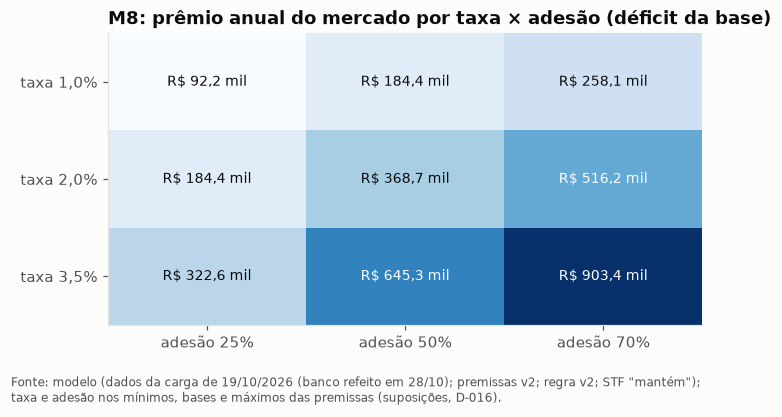

In [7]:
ses = pd.read_csv(raiz / "data/bronze/susep_ses/2026-10-17/ses_seguros_garantia.csv", sep=";", nrows=1)
print("Colunas do extrato da SES no bronze (ramos 0775 e 0776): " + ", ".join(ses.columns) + ".")
gr = mh.grade_taxa_adesao(float(oficial.valor_descoberto), semente_premissas)
display(g.tabela(gr.reset_index(), {"taxa": "pct", **{c: "reais" for c in gr.columns}})
        .rename(columns={"taxa": "taxa anual", **{c: f"adesão de {c.split('_')[1]}" for c in gr.columns}}))

fig, ax = plt.subplots(figsize=(6.5, 3.4))
im = ax.imshow(gr.to_numpy() / 1e3, cmap="Blues", aspect="auto")
ax.set_xticks(range(gr.shape[1]), [f"adesão {c.split('_')[1]}" for c in gr.columns])
ax.set_yticks(range(gr.shape[0]), [f"taxa {g.pct(t)}" for t in gr.index])
for i in range(gr.shape[0]):
    for j in range(gr.shape[1]):
        v = gr.iloc[i, j]
        ax.text(j, i, g.reais(v), ha="center", va="center", fontsize=9, color="white" if v > gr.to_numpy().mean() else g.TEXTO)
ax.grid(False)
ax.set_title("M8: prêmio anual do mercado por taxa × adesão (déficit da base)")
fig.tight_layout()
g.nota(fig, f"Fonte: modelo ({FONTE});\ntaxa e adesão nos mínimos, bases e máximos das premissas (suposições, D-016).")
g.salvar(fig, "10_grade_taxa_adesao")
plt.show()

**O que encontramos.**
- **(a) A SES não publica a importância segurada.** O extrato dos ramos 0775 e 0776 traz prêmios, sinistros, despesas e resseguro, mas nenhuma coluna de IS, e o dicionário de campos não tem nenhum item de importância segurada, capital segurado ou exposição. **A taxa média não sai da SES.** Ela só vai existir com cotações das seguradoras ou depois que o mercado começar.
- **(b) O prêmio vai de R$ 92 mil** (taxa de 1%, adesão de 25%) **a R$ 903 mil** (3,5% e 70%). A base (2%, 50%) é o centro da grade.

**O que significa para o painel.** Em vez de um número só, o simulador pode mostrar essa **grade**: deixa claro que o prêmio é praticamente "déficit × adesão × taxa", e que as duas últimas são escolhas do mercado, não dados.

**Limitações.** A grade segura o déficit no valor base. As duas premissas podem não ser independentes (uma taxa alta reduz a adesão).

## 6. M5 — O passivo de 2026 e 2027

**A pergunta.** O notebook 07 projetou o universo de 2026 e 2027 com o **passivo de 2025**. Quanto o passivo cresce até lá?

**O método.** Os mesmos vínculos da RAIS, um e dois anos depois:
- **tempo de casa + 12 meses por ano** (a conta da lei: aviso prévio, férias e multa do FGTS crescem com o tempo de serviço);
- **salário corrigido pela inflação**: o INPC dos últimos 12 meses do banco (até 09/2026), repetido em 2027 (`fonte: suposição`, como o IPCA do notebook 07).

O passivo é refeito pelas funções do modelo (`motor.calcular_serventias`). Com o universo e as classes fixos, o déficit, a IS e o prêmio do modelo são proporcionais ao passivo: o prêmio projetado do 07 é multiplicado pelo fator. Exemplo: um vínculo com 24 meses de casa e salário de R$ 3.000 passa a ter 36 meses e R$ 3.129 em 2026. Contratações e desligamentos ficam fora.

In [8]:
ins = carregar_insumos(con)
inpc, mes_inpc = pv.inflacao_recente(dados.indice_preco(con, "INPC"))
pp = mh.passivo_projetado(ins, p, limites, inpc, [1, 2])
pp["ano"] = 2025 + pp.anos_depois
display(g.tabela(pp[["ano", "passivo_todas", "passivo_universo", "valor_descoberto", "fator"]],
                 {"ano": "int", "passivo_todas": "reais", "passivo_universo": "reais", "valor_descoberto": "reais", "fator": "num3"})
        .rename(columns={"passivo_todas": "passivo de todas", "passivo_universo": "passivo das obrigadas",
                         "valor_descoberto": "déficit", "fator": "fator sobre 2025"}))
print(f"Inflação usada: INPC dos 12 meses até {mes_inpc} = {g.pct(inpc, 2)} ao ano (suposição: repetida em 2027).")
prev = con.sql("""SELECT periodo, cenario_limite, p10, central, p90 FROM gold.analise_previsao WHERE bloco = 'mercado'
                  AND medida = 'mercado_premio_emitido' AND variante = 'tendência do T2 (principal)'""").df()
prev["fator_m5"] = prev.periodo.astype(int).map(dict(zip(pp.ano, pp.fator)))
prev["central_m5"] = prev.central * prev.fator_m5
display(g.tabela(prev[["periodo", "cenario_limite", "central", "fator_m5", "central_m5"]],
                 {"central": "reais", "fator_m5": "num3", "central_m5": "reais"})
        .rename(columns={"periodo": "ano", "cenario_limite": "limite", "central": "prêmio projetado (07, passivo de 2025)",
                         "fator_m5": "fator do passivo", "central_m5": "prêmio projetado com o passivo do ano"}))

,ano,passivo de todas,passivo das obrigadas,déficit,fator sobre 2025
0,2.025,"R$ 311,9 mi","R$ 238,1 mi","R$ 36,9 mi","1,000"
1,2.026,"R$ 357,7 mi","R$ 272,3 mi","R$ 42,3 mi","1,146"
2,2.027,"R$ 401,3 mi","R$ 304,9 mi","R$ 47,4 mi","1,285"


Inflação usada: INPC dos 12 meses até 202609 = 4,29% ao ano (suposição: repetida em 2027).


,ano,limite,"prêmio projetado (07, passivo de 2025)",fator do passivo,prêmio projetado com o passivo do ano
0,2026,limite fixo,"R$ 368,8 mil","1,146","R$ 422,6 mil"
1,2026,limite corrigido pelo IPCA,"R$ 369,0 mil","1,146","R$ 422,9 mil"
2,2027,limite fixo,"R$ 367,3 mil","1,285","R$ 472,0 mil"
3,2027,limite corrigido pelo IPCA,"R$ 367,9 mil","1,285","R$ 472,8 mil"


**O que encontramos.** O passivo das obrigadas sobe **14,6% em 2026** (R$ 272,3 mi) e **28,5% em 2027** (R$ 304,9 mi). Com isso, o prêmio projetado passa de ≈ R$ 368 mil (07) para **≈ R$ 423 mil em 2026** e **≈ R$ 472 mil em 2027**, com o limite fixo ou corrigido.

**O que significa.** O achado 8 do 09 ("o universo cresce, mas o prêmio fica igual") **muda**: o prêmio cresce cerca de 15% ao ano só porque os mesmos empregados ficam mais caros de demitir. Usar o passivo de cada ano na projeção do painel fica como proposta (seção 10).

**Limitações.** Supõe os mesmos vínculos (sem contratação nem saída) e salários corrigidos só pela inflação. O efeito do tempo de casa é o maior dos dois (cerca de 10 pontos dos 14,6%).

## 7. M3 — A previsão de 2026–27: teste mais longo e faixa calibrada

**A pergunta.** A validação achou a previsão do 07 provavelmente **conservadora** (supõe +7,3% em 2026, mas o 2026-1 já estava +22% sobre o 2025-1) e as **faixas mal calibradas** (17% a 40% de cobertura). Dois testes: (b) com um teste no passado mais longo, outro método ganha? (c) A faixa cobre o que deveria? A parte (a) do plano, refazer com o 2026-1 de uma coleta nova, ficou de fora (D-046).

**O método.**
- **(b) Teste no passado mais longo:** a mesma origem móvel do T2 (treinar até uma data, prever 4 semestres, comparar com o real), com 12 origens de 2012-2 a 2023-2, em vez das 5 do T2. Entra também a média da tendência e do SARIMA. A regra do plano é escolher pela janela recente (as 5 origens do T2). **MAPE** = erro percentual médio; **viés** = se erra para cima ou para baixo.
- **(c) Cobertura honesta:** uma faixa P10–P90 deveria conter o real em ≈ 80% das vezes. Para cada previsão, montamos a faixa **só com os erros conhecidos antes dela** e contamos quantas vezes o real ficou dentro. Para a contagem de serventias acima do limite (o teste no passado do 07), a faixa calibrada é o central × (1 + P10 a P90 dos erros já conhecidos).

In [9]:
serie = dados.serie_arrecadacao(con)
pcv = cfg["previsao"]
y = pv.serie_mg(serie).loc[:pcv["ultimo_periodo"]]
metodos = {**pv.METODOS, "média da tendência e do SARIMA (M3 b)": mh.f_media_tendencia_sarima}
with warnings.catch_warnings():
    warnings.filterwarnings("ignore")
    tab_l, err_l = pv.origem_movel(y, metodos, mc_cfg["previsao"]["origens_longas"])
    tab_r, _ = pv.origem_movel(y, metodos, mc_cfg["previsao"]["origens_longas"][-mc_cfg["previsao"]["janela_recente"]:])
comp = pd.DataFrame({"MAPE: 12 origens, 2012-2 a 2023-2 (%)": tab_l.MAPE_origem_movel_pct,
                     "MAPE: 5 origens recentes, as do T2 (%)": tab_r.MAPE_origem_movel_pct,
                     "viés no teste 2024–25 (%)": tab_l.vies_teste_pct}).sort_values("MAPE: 5 origens recentes, as do T2 (%)")
display(g.tabela(comp.reset_index(names="método"), {c: "num1" for c in comp.columns}))
cob = mh.cobertura_faixa(err_l, pv.PRINCIPAL, tuple(pcv["faixa"]))
print(f"Arrecadação: a faixa P10–P90 da tendência, montada só com os erros das origens anteriores, cobriu o real em "
      f"{g.pct(cob.dentro.mean())} de {g.num(len(cob))} semestres previstos (origens 2017-2 a 2023-2).")

,método,"MAPE: 12 origens, 2012-2 a 2023-2 (%)","MAPE: 5 origens recentes, as do T2 (%)",viés no teste 2024–25 (%)
0,tendência log-linear (toda a série),"14,1","7,4","-2,1"
1,média da tendência e do SARIMA (M3 b),"11,7","7,9","-2,1"
2,"SARIMA(0,1,1)(0,1,1)2 (log)","10,7","10,5","-2,2"
3,Holt-Winters amortecido (log),"10,5","11,9","-6,0"
4,referência: último semestre,"12,5","14,8","-11,0"
5,tendência log-linear (últimos 8 semestres),"13,2","15,0","14,0"
6,sazonal + crescimento do último ano,"13,7","19,5","-9,9"
7,sazonal ingênuo (mesmo semestre do ano anterior),"16,2","20,5","-18,9"


Arrecadação: a faixa P10–P90 da tendência, montada só com os erros das origens anteriores, cobriu o real em 85,7% de 28 semestres previstos (origens 2017-2 a 2023-2).


**O que encontramos (b).**
- **No teste longo, o SARIMA e o Holt-Winters ganham** (MAPE de 10,7% e 10,5%, contra 14,1% da tendência). **Na janela recente, a tendência ganha** (7,4%, contra 10,5% do SARIMA). A média dos dois fica no meio (11,7% e 7,9%).
- Pela regra do plano (escolher pela janela recente), **a tendência continua a principal**. O SARIMA, que o 07 já mostrava como comparação, é a alternativa mais segura em prazos longos.
- **A faixa da arrecadação está bem calibrada:** cobriu o real em **86%** dos 28 semestres previstos (honesta: só com os erros anteriores).

In [10]:
media, _ = cl.receita_anual(serie)
sal = est.saltos(serie)
L = limites["classe_1_max"]
with warnings.catch_warnings():
    warnings.filterwarnings("ignore")
    bt = pv.teste_contagem(y, media, sal, list(range(int(pcv["origens"][0][:4]), pcv["ano_base"])), L)
cc_ = mh.cobertura_contagem(bt, tuple(pcv["faixa"]))
display(g.tabela(bt[["ano_base", "ano", "h", "acima_real", "acima_central", "acima_p10", "acima_p90", "dentro_da_faixa"]]
                 .merge(cc_[["ano_base", "h", "lo", "hi", "dentro"]], on=["ano_base", "h"], how="left"),
                 {"acima_real": "int", "acima_central": "int", "acima_p10": "int", "acima_p90": "int", "lo": "int", "hi": "int"})
        .rename(columns={"h": "anos à frente", "acima_real": "acima do limite: real", "acima_central": "central (07)",
                         "acima_p10": "P10 (07)", "acima_p90": "P90 (07)", "dentro_da_faixa": "dentro (07)",
                         "lo": "P10 calibrado", "hi": "P90 calibrado", "dentro": "dentro (calibrado)"}))
print(f"Cobertura da faixa do 07 (fator de MG sorteado): {g.pct(bt.dentro_da_faixa.mean())} de {g.num(len(bt))}. Faixa calibrada pelos "
      f"erros já conhecidos no ano-base (central × (1 + P10 a P90 dos erros)): {g.pct(cc_.dentro.mean())} de {g.num(len(cc_))}.")
rel = bt.acima_real / bt.acima_central - 1
print(f"Erro relativo da contagem central (real ÷ central − 1): mediana {g.pct(rel.median())}, de {g.pct(rel.min())} a {g.pct(rel.max())}; "
      f"o central erra para baixo em {g.num((rel > 0).sum())} de {g.num(len(rel))} casos.")

,ano_base,ano,anos à frente,acima do limite: real,central (07),P10 (07),P90 (07),dentro (07),P10 calibrado,P90 calibrado,dentro (calibrado)
0,2019,2020,1,713,841,718,867,False,—,—,NaN
1,2019,2021,2,877,917,756,879,True,—,—,NaN
2,2020,2021,1,878,878,761,828,False,—,—,NaN
3,2020,2022,2,982,954,779,848,False,—,—,NaN
4,2021,2022,1,983,958,805,876,False,—,—,NaN
5,2021,2023,2,1.050,1.040,852,986,False,—,—,NaN
6,2022,2023,1,1.057,1.044,888,1.033,False,930,1.073,True
7,2022,2024,2,1.147,1.123,933,1.163,True,1.001,1.154,True
8,2023,2024,1,1.147,1.137,980,1.173,True,1.038,1.168,True
9,2023,2025,2,1.280,1.202,1.017,1.236,False,1.097,1.235,False


Cobertura da faixa do 07 (fator de MG sorteado): 27,3% de 11. Faixa calibrada pelos erros já conhecidos no ano-base (central × (1 + P10 a P90 dos erros)): 60,0% de 5.
Erro relativo da contagem central (real ÷ central − 1): mediana 1,2%, de -15,2% a 6,5%; o central erra para baixo em 8 de 11 casos.


**O que encontramos (c).**
- **A faixa da contagem acima do limite do 07 cobre só 27%** (3 de 11). Ela sai só do crescimento de MG sorteado e não inclui o erro de cada serventia: fica estreita e às vezes nem contém o central.
- **A faixa calibrada pelos erros passados cobre 60%** (3 de 5): melhor, mas com poucos casos. Os dois que ficam fora são 2025, quando o crescimento acelerou.
- O central erra para baixo em 8 de 11 casos (mediana +1,2%), o mesmo sinal de previsão conservadora.

**Correção proposta:** na projeção do painel, usar a faixa calibrada para a contagem acima do limite e rotular as faixas das outras medidas como "só a incerteza do crescimento de MG".

## 8. M4 — Subidas de classe: o desvio condicionado resolve a diferença entre o 07 e o 05b?

**A pergunta.** O 05b (floresta) prevê 145 subidas da Classe 1 para a 2 em 2026; o 07, 78. A diferença vem de o 07 sortear o crescimento de cada serventia sem olhar o passado dela?

**O método.** O 07 sorteia o **desvio** de cada serventia (quanto ela cresce acima ou abaixo de MG) entre todos os desvios do passado. A M4 sorteia só entre as serventias que cresceram **parecido no ano anterior** (o mesmo tercil de crescimento), porque crescimento costuma persistir. O teste é o do 07: com o ano-base b, projetar as subidas de b+1 e b+2 e comparar com as reais. Junto, a contagem com o crescimento **real** de MG (diagnóstico: quanto do erro vem da previsão de MG).

In [11]:
with warnings.catch_warnings():
    warnings.filterwarnings("ignore")
    ts = mh.teste_subidas(y, media, sal, list(range(int(pcv["origens"][0][:4]), pcv["ano_base"])), L)
ts = ts.merge(bt[["ano_base", "h", "subidas_central_fator_real"]], on=["ano_base", "h"])
display(g.tabela(ts[["ano_base", "ano", "h", "subidas_real", "subidas_pool_inteiro", "subidas_condicionado", "subidas_central_fator_real"]],
                 {"subidas_real": "int", "subidas_pool_inteiro": "int", "subidas_condicionado": "int", "subidas_central_fator_real": "int"})
        .rename(columns={"h": "anos à frente", "subidas_real": "subidas: real", "subidas_pool_inteiro": "07 (desvio do pool inteiro)",
                         "subidas_condicionado": "M4 (desvio condicionado)", "subidas_central_fator_real": "07 com o fator real de MG"}))
erros_sub = pd.DataFrame({"07": (ts.subidas_pool_inteiro - ts.subidas_real).abs(),
                          "M4": (ts.subidas_condicionado - ts.subidas_real).abs(),
                          "07 com o fator real": (ts.subidas_central_fator_real - ts.subidas_real).abs()})
print("Erro absoluto médio das subidas: " + "; ".join(f"{k}: {g.num(v, 1)}" for k, v in erros_sub.mean().items()) +
      f". Viés médio do 07: {g.num((ts.subidas_pool_inteiro - ts.subidas_real).mean(), 1)}; com o fator real: "
      f"{g.num((ts.subidas_central_fator_real - ts.subidas_real).mean(), 1)}.")

,ano_base,ano,anos à frente,subidas: real,07 (desvio do pool inteiro),M4 (desvio condicionado),07 com o fator real de MG
0,2019,2020,1,64,156,156,48
1,2019,2021,2,208,235,236,189
2,2020,2021,1,179,172,175,165
3,2020,2022,2,274,249,255,282
4,2021,2022,1,124,103,98,135
5,2021,2023,2,195,183,176,189
6,2022,2023,1,96,87,86,84
7,2022,2024,2,184,164,161,159
8,2023,2024,1,124,105,107,101
9,2023,2025,2,257,179,181,215


Erro absoluto médio das subidas: 07: 33,5; M4: 33,9; 07 com o fator real: 18,5. Viés médio do 07: -11,9; com o fator real: -15,0.


**O que encontramos.**
- **O desvio condicionado não melhora:** erro médio de 33,9 subidas, contra 33,5 do 07. **A M4 foi rejeitada.**
- **Com o crescimento real de MG, o erro cai pela metade** (18,5). O erro das subidas vem quase todo da **previsão de MG** (o fator conservador da M3), e não da dispersão entre serventias. Em 2025, por exemplo: 257 subidas reais, 179 no 07, 215 com o fator real.

**O que significa.** As duas contagens (07 e 05b) só vão convergir com uma previsão de MG melhor (seção 7). O 05b não depende do fator de MG e por isso dá mais subidas.

**Limitações.** 11 casos no teste, com anos de crescimento muito diferentes (2020 a 2025).

## 9. M6 — Universo: a leitura da norma

**A pergunta.** (a) Qual é a faixa do universo entre as duas leituras da receita? (b) A regra do salto grosseiro (serventias 042986, 035030, 059816 e 046219, notebooks 01 e 07) era decisão do autor.

**O método.** (a) A `gold.analise_sensibilidade_metodo` (D-042, D-044): base (arrecadação) e leitura literal do art. 2º, XXIV (arrecadação − repasse). A parte (c) do plano, conferir as quatro serventias numa coleta nova, ficou de fora (D-046).

In [12]:
sm = con.sql("SELECT chave, rotulo, n_universo, mercado_premio_emitido, var_n_universo, var_mercado_premio_emitido FROM gold.analise_sensibilidade_metodo WHERE chave IN ('base', 'receita_liquida')").df()
display(g.tabela(sm, {"n_universo": "num1", "mercado_premio_emitido": "reais", "var_n_universo": "pct", "var_mercado_premio_emitido": "pct"})
        .rename(columns={"n_universo": "obrigadas", "mercado_premio_emitido": "prêmio", "var_n_universo": "Δ obrigadas",
                         "var_mercado_premio_emitido": "Δ prêmio"}))

,chave,rotulo,obrigadas,prêmio,Δ obrigadas,Δ prêmio
0,base,Base (arrecadação; D-015 e D-022),"1.121,3","R$ 368,7 mil","0,0%","0,0%"
1,receita_liquida,"Leitura literal do art. 2º, XXIV: arrecadação ...","893,6","R$ 337,4 mil","-20,3%","-8,5%"


**O que encontramos.**
- (a) Pela leitura literal, o universo cai **20,3%** (1.121,3 → 893,6) e o prêmio, 8,5% (R$ 368,7 → 337,4 mil).

**O que significa.** (a) O universo deve ser mostrado como **faixa entre as leituras: 894 a 1.121 obrigadas** (prêmio de R$ 337 a 369 mil), com a base em destaque, como a D-042 já propõe. (b) **Decidido em 28/10 (D-046):** a classe continua com o valor declarado ao CNJ; o pipeline avisa os saltos grosseiros do ano da classe (`qualidade.checagens`) e a `gold.analise_sensibilidade_metodo` ganha a linha "sem os saltos" (efeito do notebook 01: cerca de −11 obrigadas, −1%).

**Limitações.** Sem uma coleta nova, não sabemos se os cartórios corrigiram as declarações depois de 18/10.

## 10. Resumo: o que muda nas conclusões

| Melhoria | Resultado | Efeito no 09 e no painel |
|---|---|---|
| M1 | Pela renda, poucas obrigadas têm déficit (7% e 10%), mas grande; o total fica perto do modelo (R$ 34,5 mi × R$ 36,9 mi) | O déficit (número 7) é defensável; a chance e a parte descoberta por classe estão erradas na forma |
| M10 | As providas grandes têm 85% do déficit pela M1 (55% no modelo) | Achado do cliente do seguro mais forte |
| M2 | Com a M1, sinistralidade de 12% a 46% e lucro técnico de R$ 106 a 231 mil/ano; sem ela, prejuízo | A pergunta 9 passa a ter resposta, condicionada a quem paga quando a delegação termina |
| M7 | Prêmio só existe se a regra for mantida; ADI sem liminar em 28/10 | Prêmio condicionado ao cenário do STF no painel |
| M8 | A SES não publica a IS; grade de R$ 92 mil a R$ 903 mil | Grade taxa × adesão no simulador |
| M5 | Passivo +14,6% em 2026 e +28,5% em 2027 | Prêmio projetado ≈ R$ 423 mil (2026) e ≈ R$ 472 mil (2027), não "igual" |
| M3 | No teste longo, o SARIMA erra menos; na janela recente, a tendência continua melhor; faixa da arrecadação com 86% de cobertura, a da contagem só 27% (calibrada: 60%) | Tendência segue a principal; faixa da contagem calibrada (proposta) |
| M4 | Rejeitada: o erro das subidas vem da previsão de MG | A diferença 07 × 05b depende de uma previsão de MG melhor |
| M6 | Universo de 894 a 1.121 obrigadas entre as leituras | Faixa do universo no painel (D-042); regra do salto decidida (D-046) |

**Decidido pelo autor em 28/10 (D-046):**
1. **Recalibrar a chance e a parte descoberta do déficit pela M1**, depois de conferir as 50 obrigadas com saldo ≤ 0: premissas v3. Os 10 números mudam (notebook 09).
2. **Regra do salto:** o valor declarado fica na classe; aviso no pipeline e linha "sem os saltos" na sensibilidade.
3. **Sem coleta nova:** os dados continuam os de 17 e 18/10. A M9 e as partes das M3 e M6 que dependiam de uma coleta nova ficaram de fora.

**Propostas que continuam abertas:** no painel, prêmio condicionado ao cenário do STF (M7), grade taxa × adesão (M8), projeção com o passivo do ano (M5) e a pergunta 9 com as duas leituras (M2).

**Tabelas para o painel** (Etapa 2; gravadas pelo pipeline, D-045): `analise_capacidade_faixas`, `analise_capacidade_calibracao`, `analise_sinistro`, `analise_premio_cenarios` e `analise_premio_grade`.